<p style="text-align:center"><img src="../images/01_banner_vector.png" alt="Working with Vector Data" width="100%"></p>


# Geometry Operations

This notebook introduces how to perform geometry operations on vector data using the GeoLattice library.
Geometry operations allow you to create, modify, and analyze geometric features, such as points, lines, and polygons, using powerful, easy-to-use Python tools.
We'll demonstrate common workflows including constructing new geometries, transforming and cleaning shapes, and measuring key properties of spatial features.


## Overview

Geometry operations build new features from points, lines, and polygons, and they clean coordinates before area, length, or a map is published.

GeoLattice implements these tools in `geolattice.vector.geometry_tools` and exports them from `geolattice.vector`. They use [Shapely](https://shapely.readthedocs.io/) and return a GeoDataFrame when [GeoPandas](https://geopandas.org/) is installed.

Shapefiles are opened with `open_vectors_data()`. Maps use `plot_layer()`, `plot_layers()`, `plot_pair()`, and `style_axes()` from `geolattice.viz`.

The notebook is organized in three parts:

1. **Load data**: US states, counties, Colorado soil samples, Onondaga streets, and Yellowstone.
2. **Construct geometry**: bounding boxes, offsets, points along lines, rectangles/ovals/diamonds, transects, transforms, orthogonalize, and snap.
3. **Measure and clean**: geometry attributes, collect, centroids, displacement, validity, duplicate vertices, and holes.

Sample files live in `Data/00_shared/vector_data/USA`.


## Setup

The next cell finds the repository root, puts it on the import path, applies the tutorial map style, and defines `read_layer` for shapefiles under `Data/00_shared/vector_data/USA`.

Geometry tools are imported from `geolattice.vector`. Maps use `plot_layer`, `plot_layers`, `plot_pair`, and `style_axes` from `geolattice.viz`.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup.
import sys  # mutate sys.path so geolattice can be imported from the repo root
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame constructors and CRS handling
import matplotlib.pyplot as plt  # figure and axes creation for custom maps
import pandas as pd  # tabular display options
from IPython.display import display  # rich table previews in the notebook
from shapely.geometry import Point, Polygon  # build points and hole rings



In [2]:
# ===================================================================
# Setup and helpers for geometry operations and maps.
# Walk up from the working directory to the repo root, import GeoLattice tools,
# point DATA at the sample folder, and define read_layer().
# ===================================================================

# Resolve the current working directory to an absolute Path.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "vector_data").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/vector_data from the working directory.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Geometry construction / cleanup helpers exported from geolattice.vector.
from geolattice.vector import (
    add_geometry_attributes,  # area, perimeter, length, x/y columns
    affine_transform,  # scale, then rotate, then translate
    build_sections,  # rectangle grid or attribute-based dissolve sections
    centroids,  # center of mass for each feature
    check_validity,  # is_valid flag and reason per feature
    collect_geometries,  # multipart collect without dissolving overlaps
    delete_holes,  # remove interior rings from polygons
    diamonds,  # diamond polygons centered on points
    fix_geometries,  # repair invalid geometries
    offset_lines,  # parallel copies of a line
    open_vectors_data,  # open a shapefile (or other vector source)
    oriented_minimum_bounding_box,  # rotated enclosing rectangle
    orthogonalize,  # square near-right-angle corners
    ovals,  # ellipse polygons centered on points
    point_on_surface,  # guaranteed-interior label point
    points_along_geometry,  # stations spaced along a line
    points_displacement,  # spread stacked points onto a circle
    rectangles,  # axis-aligned then rotated rectangles on points
    remove_duplicate_vertices,  # drop near-duplicate consecutive vertices
    rotate,  # rotate features about a shared or per-feature origin
    snap_geometries_to_layer,  # snap vertices onto a reference layer
    snap_points_to_grid,  # round vertices to a regular grid
    transect,  # cross-path lines at an interval
    translate,  # shift features by a fixed x/y offset
)
# Shared map styling helpers from geolattice.viz.
from geolattice.viz import EDGE, FACE, apply_map_style, plot_layer, plot_layers, plot_pair, style_axes

# Sample vector data for this tutorial.
DATA = ROOT / "Data" / "00_shared" / "vector_data" / "USA"
assert DATA.is_dir(), DATA  # fail early if the folder is missing

# Keep printed attribute tables readable in the notebook.
pd.set_option("display.max_columns", 12)  # show up to 12 columns
pd.set_option("display.max_colwidth", 48)  # truncate long string cells
pd.set_option("display.width", 120)  # wider console wrapping for tables
# Apply the shared GeoLattice map style (fonts, colors, spines).
apply_map_style()


# helper: open one shapefile under DATA as a GeoDataFrame
def read_layer(relative):
    # short description of what read_layer returns
    """Open one shapefile and return a GeoDataFrame without the reader fid."""
    # Build an absolute path under DATA from a relative shapefile path.
    path = DATA / relative
    # Open the vector dataset and convert it to a pandas/GeoPandas table.
    with open_vectors_data(path) as dataset:
        frame = dataset.to_dataframe()  # attribute table plus geometry column
        crs = frame.crs  # coordinate reference system of the layer
    # Drop the driver-added fid column when present so demos stay tidy.
    if "fid" in frame.columns:
        frame = frame.drop(columns="fid")  # remove the driver-added fid column
    # Rebuild an explicit GeoDataFrame with the preserved CRS.
    return gpd.GeoDataFrame(frame, geometry="geometry", crs=crs)


# Confirm which folder the notebook will read from.
print(f"Data folder: {DATA}")



Data folder: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/USA


## Available operations

Each function below is imported from `geolattice.vector`.

| Operation | Function | What it does |
|---|---|---|
| Rectangles | `rectangles()` | Builds a rectangle centered on each point. `width` runs east-west and `height` runs north-south, then `angle` rotates the polygon. A multipoint becomes one rectangle per part. |
| Ovals | `ovals()` | Builds an ellipse centered on each point. `width` and `height` are the full axis lengths. `quad_segs` is the number of segments used for a quarter of the ellipse. |
| Diamonds | `diamonds()` | Builds a diamond centered on each point. `width` is the horizontal diagonal and `height` is the vertical diagonal before rotation. |
| Oriented minimum bounding box | `oriented_minimum_bounding_box()` | Builds the rotated rectangle that encloses the layer, or each feature when `per_feature=True`. Returns `angle`, `width` (longer side), and `height` (shorter side). |
| Rotate | `rotate()` | Rotates features counterclockwise about one origin. `"center"` uses the middle of the layer bounds, `"centroid"` uses the combined centroid, `"feature"` uses each feature's own centroid, and `(x, y)` uses that point. |
| Affine transform | `affine_transform()` | Scales, then rotates, then translates, in that order, about the same kinds of origin as `rotate()`. `scale` is one number or an `(x_scale, y_scale)` pair. `translation` is an `(x, y)` shift applied after rotation. |
| Translate | `translate()` | Shifts every feature by the same `xoff`, `yoff`, and optional `zoff`. |
| Offset lines | `offset_lines()` | Copies each line into parallel lines. `side` is `"left"`, `"right"`, or `"both"`. `count` is the number of copies on each requested side. The result adds `offset_index` and `offset_distance`. A polygon is offset along its exterior ring. |
| Points along a line | `points_along_geometry()` | Places points along each line at a fixed spacing. `start_offset` skips the beginning and `end_offset` leaves the end unused. Each point keeps the source attributes and records `distance_along`. |
| Transects | `transect()` | Draws lines across a path. `interval` is the spacing along the path; when it is omitted, a transect is drawn at each vertex. `angle` is measured from the path direction, so 90 is perpendicular and points to the left. `length` is the full length when `side` is `"both"`. |
| Orthogonalize | `orthogonalize()` | Squares corners that are already within `angle_tolerance` degrees of 90. Neighboring vertices stay fixed. Line endpoints stay where they are. Rings and holes are squared on their own. |
| Snap points to a grid | `snap_points_to_grid()` | Rounds every vertex to the nearest intersection of a regular grid. `spacing_y` defaults to `spacing_x`. `origin_x` and `origin_y` locate one grid intersection. Z values stay unchanged. |
| Snap geometries to a layer | `snap_geometries_to_layer()` | Moves vertices onto a reference layer when they are within `tolerance`. `mode` is `"vertices"`, `"segments"`, or `"vertices_and_segments"`. Passing the same layer as both inputs collapses vertices that should share an edge. |
| Build sections | `build_sections()` | In grid mode, lays out a rows-by-columns rectangle grid. `origin` is the southwest corner before `angle` is applied. Each cell is named `R{row}C{column}`. In attribute mode, `by` unions features that share a value and adds `n_features`. |
| Geometry attributes | `add_geometry_attributes()` | Writes polygon `area` and `perimeter`, line `length`, and point `x`, `y`, and `z` when a point has a height. A column is added only for geometry types that are present. |
| Collect geometries | `collect_geometries()` | Groups features into one multipart geometry. Overlaps stay as separate parts. Mixed types become a `GeometryCollection`. `n_features` counts the features in the part. |
| Centroids | `centroids()` | Creates the centroid of each feature. The centroid of a concave polygon can fall outside the polygon. |
| Point on surface | `point_on_surface()` | Creates one point that lies inside each feature. For a polygon it is on the surface, for a line it is on the line, and for a point it is the point itself. |
| Points displacement | `points_displacement()` | Spreads point features that were recorded at the same location onto a circle of radius `distance`. `proximity` is how close points must be to belong to one stack. `proximity=0` treats coordinates that match to 8 decimal places as one stack. |
| Check validity | `check_validity()` | Adds `is_valid` and `validity_reason`. `invalid_only=True` drops the valid rows. |
| Fix geometries | `fix_geometries()` | Repairs invalid geometries. `method="make_valid"` keeps the original vertex locations. `method="buffer"` uses a zero-width buffer. Valid geometries are copied through unchanged. |
| Remove duplicate vertices | `remove_duplicate_vertices()` | Drops consecutive vertices closer than `tolerance`. `tolerance=0` removes exact duplicates only. A ring that no longer has three distinct corners becomes empty. |
| Delete holes | `delete_holes()` | Removes interior rings from polygons. `minimum_area=0` deletes every hole. A positive value deletes only holes smaller than that area. Lines and points pass through unchanged. |

### Shared rules

Angles are degrees counterclockwise from east, the positive X axis. The `angle` returned by `oriented_minimum_bounding_box()` can be passed straight to `rectangles()`, `ovals()`, `diamonds()`, `rotate()`, and `affine_transform()`.

Distances, widths, heights, and tolerances are in the coordinate units of the layer. The layers in this notebook use an Albers projection in metres, so `40` means 40 metres. On a geographic layer those numbers are degrees. The tools warn when that happens. Project the layer to a metre or foot CRS before using a ground distance.

`width`, `height`, `angle`, and `distance` accept a single number, a sequence with one value per feature, or the name of a numeric attribute.

A function accepts a GeoDataFrame, a GeoSeries, a pandas DataFrame with a geometry column, a Shapely geometry, WKT, a GeoJSON geometry mapping, a sequence of those, a sequence of `VectorFeature`, or an open vector layer.


## Part 1: Load data


### Layers

The shapefiles are in `Data/00_shared/vector_data/USA`:

* US state boundaries (`US_STATE.shp`)
* US county boundaries (`US_COUNTY.shp`)
* Colorado soil-sample points (`CO_SOC_data.shp`)
* Onondaga County street centerlines (`Ononda_Street_PROJ.shp`)
* Yellowstone National Park boundary (`Yellow_Stone.shp`), published by the National Park Service on [Data.gov](https://catalog.data.gov/dataset/national-park-boundariesf0a4c)

The state and county layers, the streets, and the park boundary are in a metre-based Albers projection.

The geometry stored in `CO_SOC_data.shp` keeps the easting in the `x` field and a shifted northing. The `x` and `y` fields are the Albers coordinates that fall inside Colorado. The notebook rebuilds the point geometry from those fields and assigns the CRS of `US_STATE.shp`.

Line examples use North Road, the longest street segment in the Onondaga layer. Polygon cleanup uses Broomfield County, which has two interior rings. Region examples use the state layer.


In [3]:
# Load the layers used throughout the geometry demos and fix sample coordinates.
states = read_layer("US_STATE.shp")  # US state boundaries
counties = read_layer("US_COUNTY.shp")  # US county boundaries
streets = read_layer("Ononda_Street_PROJ.shp")  # Onondaga street centerlines
park = read_layer("Yellow_Stone.shp")  # Yellowstone park boundary
samples_raw = read_layer("CO_SOC_data.shp")  # Colorado soil samples (raw geometry)

# Median offset between attribute y and stored geometry northing (diagnostic).
northing_shift = float((samples_raw["y"] - samples_raw.geometry.y).median())
# Rebuild point geometry from the Albers x/y attribute fields.
samples = samples_raw.set_geometry(gpd.points_from_xy(samples_raw["x"], samples_raw["y"]))
# Assign the same CRS as the state layer so overlays measure in metres.
samples = samples.set_crs(states.crs)

# Colorado-focused subsets used by later cells.
colorado = states.loc[states["STATE"] == "Colorado"].copy()  # state outline
co_counties = counties.loc[counties["STATE"] == "Colorado"].copy()  # CO counties
broomfield = co_counties.loc[co_counties["COUNTY"] == "Broomfield County"].copy()  # hole demo
# Longest street segment becomes the "North Road" example line.
road = streets.loc[[streets.geometry.length.idxmax()]].copy()

# Count samples that fall inside the Colorado polygon after the rebuild.
inside = int(samples.within(colorado.geometry.iloc[0]).sum())
print(f"Northing shift in CO_SOC_data.shp: {northing_shift:,.1f} m")  # print a short status line
print(f"Soil samples inside Colorado: {inside} of {len(samples)}")  # print a short status line
print(f"Colorado counties: {len(co_counties)}")  # print a short status line
print(f"Street segments: {len(streets)}")  # print a short status line
# Identify the road name and length used in later cells.
print(
    f"Road used below: {road['CompleteSt'].iloc[0]} "  # road name from the CompleteSt field
    f"({road.geometry.length.iloc[0]:,.0f} m)"  # road length in metres, formatted for the print
# close the function call
)
# Preview a few sample attributes.
display(samples[["ID", "COUNTY", "SOC", "Longitude", "Latitude"]].head())



Northing shift in CO_SOC_data.shp: 1,606,786.3 m
Soil samples inside Colorado: 136 of 136
Colorado counties: 64
Street segments: 999
Road used below: North Road (3,525 m)


,ID,COUNTY,SOC,Longitude,Latitude
0,1,Moffat County,6.439,-109.04304,40.44604
1,2,Montezuma County,2.821,-108.91701,37.58697
2,3,Mesa County,2.760,-108.87637,39.21424
3,4,Mesa County,10.535,-108.79555,38.84402
4,5,Garfield County,5.528,-108.74193,39.50625


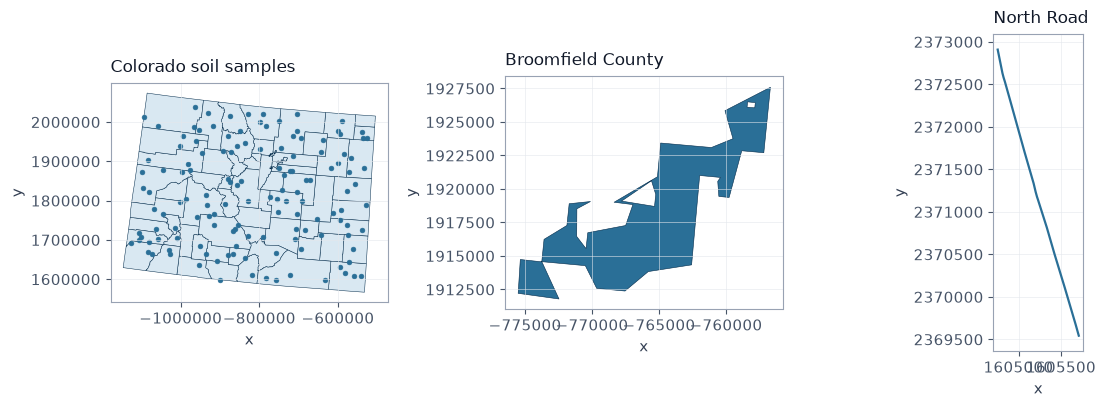

In [4]:
# Three-panel overview: Colorado samples, Broomfield, and North Road.
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))  # one row, three maps
# Left: counties under soil-sample points.
plot_layer(co_counties, ax=axes[0], facecolor="#D9E8F2", edgecolor=EDGE, linewidth=0.35, show=False)
plot_layer(samples, ax=axes[0], facecolor=FACE, markersize=12, show=False)
style_axes(axes[0], "Colorado soil samples")  # apply shared axis styling and title

# Middle: Broomfield County polygon (includes holes).
plot_layer(broomfield, "Broomfield County", ax=axes[1], linewidth=0.4, show=False)

# Right: the longest Onondaga street segment.
plot_layer(road, "North Road", ax=axes[2], edgecolor=FACE, linewidth=1.6, show=False)
fig.tight_layout()  # tighten subplot spacing
plt.show()  # render the figure



## Part 2: Construct geometry

### Oriented minimum bounding box

`oriented_minimum_bounding_box()` returns the rotated rectangle around the features. `width` is the longer side and `height` is the shorter side. `angle` is the direction of the long side, in degrees counterclockwise from east, folded into the range (-90, 90].

With `per_feature=False` the box encloses the whole layer and the result has one row. With `per_feature=True` each feature keeps its attributes and gets its own box.

The park box describes Yellowstone. The road angle is saved for the plot polygons further down, so those polygons follow North Road.


In [5]:
# Oriented minimum bounding boxes for Yellowstone, North Road, and CO counties.
park_box = oriented_minimum_bounding_box(park)  # one box around the whole park
road_box = oriented_minimum_bounding_box(road)  # one box around North Road
# Long-side angle (degrees CCW from east) reused when building plot polygons.
road_angle = float(road_box["angle"].iloc[0])

# Convert park box width/height to kilometres for a compact summary table.
park_summary = park_box[["angle", "width", "height", "n_features"]].copy()
park_summary["width_km"] = park_summary["width"] / 1000  # metres to km
park_summary["height_km"] = park_summary["height"] / 1000
display(park_summary[["angle", "width_km", "height_km", "n_features"]])  # preview the table in the notebook
print(f"North Road long-side angle: {road_angle:.2f} degrees")  # print a short status line
print(f"North Road box: {road_box['width'].iloc[0]:,.0f} m by {road_box['height'].iloc[0]:,.1f} m")  # print a short status line

# One oriented box per Colorado county, keeping county attributes.
county_boxes = oriented_minimum_bounding_box(co_counties, per_feature=True)
# Show the five widest counties with width/height in kilometres.
display(
    county_boxes[["COUNTY", "angle", "width", "height"]]  # start from county box attributes
    # add width_km and height_km derived columns
    .assign(width_km=lambda frame: frame["width"] / 1000, height_km=lambda frame: frame["height"] / 1000)
    .sort_values("width", ascending=False)  # widest counties first
    .head(5)  # keep only the top rows for display
    .loc[:, ["COUNTY", "angle", "width_km", "height_km"]]  # select the columns shown in the table
# close the function call
)



,angle,width_km,height_km,n_features
0,81.252061,108.887205,105.063496,1


North Road long-side angle: -74.19 degrees
North Road box: 3,524 m by 27.9 m


,COUNTY,angle,width_km,height_km
61,Las Animas County,-5.082474,182.796653,92.335880
2,Garfield County,-7.171781,171.685362,81.513633
5,Rio Blanco County,-7.159240,170.779811,64.553695
0,Moffat County,-7.430969,146.065711,87.837826
34,Mesa County,-7.403218,144.387486,97.403406


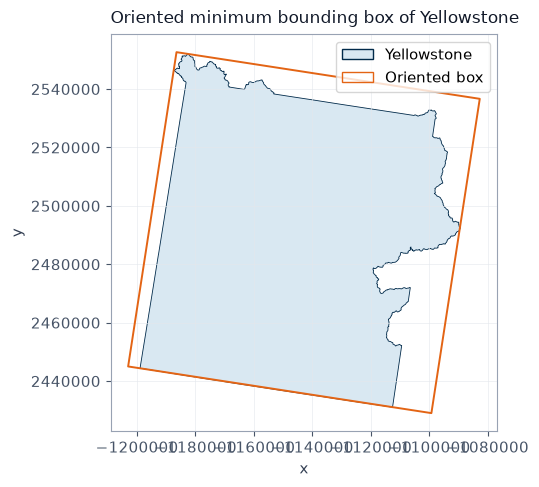

<Axes: title={'left': 'Oriented minimum bounding box of Yellowstone'}, xlabel='x', ylabel='y'>

In [6]:
# Map Yellowstone with its oriented minimum bounding box outline.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        # Park fill under the box edge.
        {"data": park, "label": "Yellowstone", "facecolor": "#D9E8F2", "edgecolor": EDGE, "linewidth": 0.6},
        # Oriented box drawn as an unfilled orange outline.
        {"data": park_box, "label": "Oriented box", "facecolor": "none", "edgecolor": "#E36414", "linewidth": 1.4},
    ],
    title="Oriented minimum bounding box of Yellowstone",  # map title
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Offset lines

`offset_lines()` copies a surveyed line into parallel lines. Positive `distance` is the spacing. Left and right follow the direction of the line. `offset_index` is negative on the right, zero on the source line, and positive on the left. `offset_distance` is the signed spacing.

Here North Road is copied three times to each side at 40 metre spacing, and the source line is kept.


,CompleteSt,offset_index,offset_distance
0,North Road,-3,-120.0
1,North Road,-2,-80.0
2,North Road,-1,-40.0
3,North Road,0,0.0
4,North Road,1,40.0
5,North Road,2,80.0
6,North Road,3,120.0


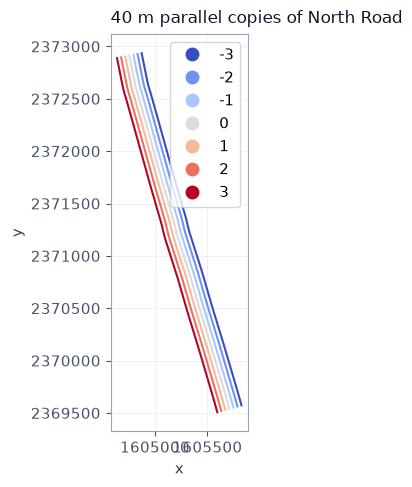

<Axes: title={'left': '40 m parallel copies of North Road'}, xlabel='x', ylabel='y'>

In [7]:
# Build parallel copies of North Road at 40 m spacing on both sides.
parallel = offset_lines(road, 40, count=3, side="both", keep_original=True)
# Show offset_index (signed side) and offset_distance for each copy.
display(parallel[["CompleteSt", "offset_index", "offset_distance"]])
# Color the copies by offset_index so left/right are easy to see.
plot_layer(
    parallel,  # GeoDataFrame of offset line copies
    "40 m parallel copies of North Road",  # keyword or positional argument continued
    column="offset_index",  # categorical color by copy index
    categorical=True,
    cmap="coolwarm",  # colormap name
    linewidth=1.5,  # outline width
    legend=True,  # show a legend
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Points along a line

`points_along_geometry()` walks each line and drops a point every `distance`. `start_offset` and `end_offset` keep the points off the two ends. `distance_along` is the distance from the start of that line.

The stations below start 100 metres along North Road and repeat every 200 metres, stopping 100 metres before the end.


Stations: 17


,CompleteSt,distance_along
0,North Road,100.0
1,North Road,300.0
2,North Road,500.0
3,North Road,700.0
4,North Road,900.0


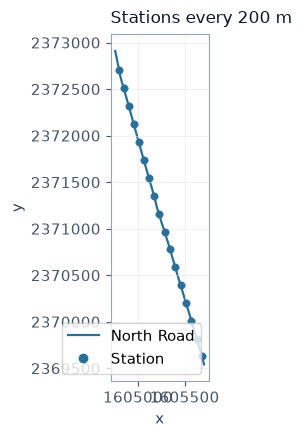

<Axes: title={'left': 'Stations every 200 m'}, xlabel='x', ylabel='y'>

In [8]:
# Place stations along North Road every 200 m, inset 100 m from each end.
stations = points_along_geometry(road, 200, start_offset=100, end_offset=100)
print(f"Stations: {len(stations)}")  # print a short status line
# distance_along is metres from the start of the line.
display(stations[["CompleteSt", "distance_along"]].head())
# Overlay stations on the road centerline.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        {"data": road, "label": "North Road", "edgecolor": EDGE, "linewidth": 1.6},  # one map layer: data plus draw style
        {"data": stations, "label": "Station", "facecolor": FACE, "markersize": 28},  # one map layer: data plus draw style
    ],  # close the function call
    title="Stations every 200 m",  # map title
    figsize=(7, 4.5),  # figure width and height in inches
# close the function call
)



### Rectangles, ovals, and diamonds

`rectangles()`, `ovals()`, and `diamonds()` turn each point into a plot polygon of a fixed size. The polygon is built axis-aligned, then rotated by `angle`. Passing the long-side angle from the bounding box turns the width so it follows the road.

Each plot here is 80 metres along the road and 36 metres across it. A rectangle's area is `width * height`. A diamond's area is half of that. An oval's area is the ellipse with those full axis lengths. `quad_segs` controls how smoothly the oval is drawn.


Rectangle area: 2,880.0 square metres
Oval area:      2,260.3 square metres
Diamond area:   1,440.0 square metres


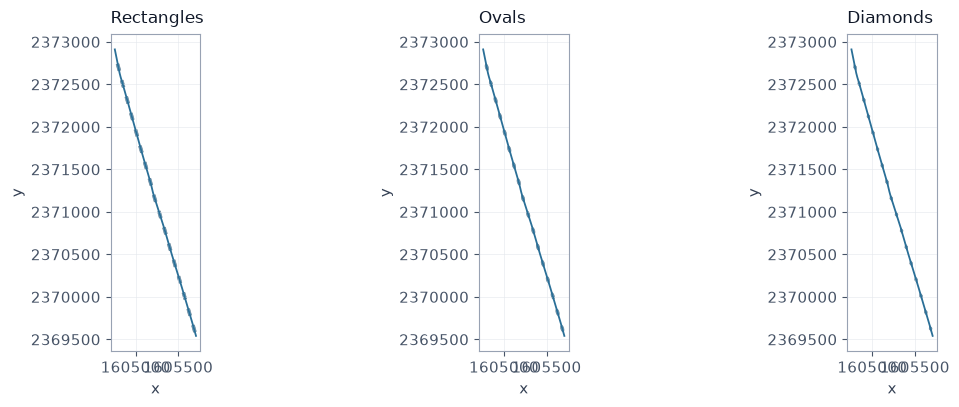

In [9]:
# Turn each station into 80 x 36 m plot polygons rotated to the road angle.
rect_plots = rectangles(stations, 80, 36, angle=road_angle)  # rectangles
oval_plots = ovals(stations, 80, 36, angle=road_angle, quad_segs=24)  # ellipses
diamond_plots = diamonds(stations, 80, 36, angle=road_angle)  # diamonds

# Compare areas of the first polygon of each type (CRS square metres).
print(f"Rectangle area: {rect_plots.geometry.area.iloc[0]:,.1f} square metres")
print(f"Oval area:      {oval_plots.geometry.area.iloc[0]:,.1f} square metres")  # print a short status line
print(f"Diamond area:   {diamond_plots.geometry.area.iloc[0]:,.1f} square metres")  # print a short status line

# Three side-by-side maps, one shape family each.
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
# iterate over panels (or rows) to draw each map
for ax, layer, title in zip(
    axes,  # one axes per plot shape family
    [rect_plots, oval_plots, diamond_plots],  # rectangle, oval, and diamond layers
    ["Rectangles", "Ovals", "Diamonds"],  # panel titles matching each layer
):  # end of the for-loop header
    # Draw the road under the plot polygons.
    plot_layer(road, ax=ax, edgecolor=EDGE, linewidth=1.3, show=False)
    # Semi-transparent plots on top.
    plot_layer(layer, title, ax=ax, alpha=0.55, linewidth=0.4, show=False)
fig.tight_layout()  # tighten subplot spacing
plt.show()  # render the figure



### Transects

`transect()` draws a line across the path. `interval` is the distance along the path between transects. `length` is the full transect length when `side` is `"both"`, and the path sits in the middle. An angle of 90 degrees is perpendicular to the path and points to the left of the line direction.

These dividers are 160 metres long and repeat every 200 metres, including one at the start and one at the end of North Road.


Transects: 19


,distance_along
0,0.0
1,200.0
2,400.0
3,600.0
4,800.0


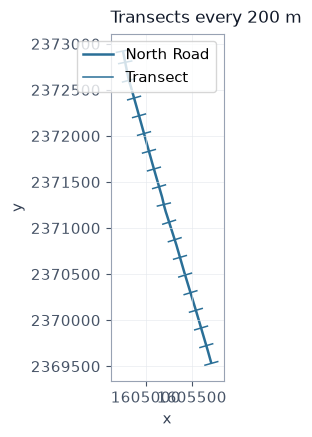

<Axes: title={'left': 'Transects every 200 m'}, xlabel='x', ylabel='y'>

In [10]:
# Draw 160 m perpendicular transects every 200 m along North Road.
dividers = transect(road, length=160, interval=200)
print(f"Transects: {len(dividers)}")  # print a short status line
# distance_along marks where each transect crosses the path.
display(dividers[["distance_along"]].head())
# Overlay orange transect lines on the road.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        {"data": road, "label": "North Road", "edgecolor": EDGE, "linewidth": 1.8},  # one map layer: data plus draw style
        {"data": dividers, "label": "Transect", "edgecolor": "#E36414", "linewidth": 1.1},
    ],
    title="Transects every 200 m",  # map title
    figsize=(7, 4.5),  # figure width and height in inches
# close the function call
)



### Rotate, translate, and affine transform

`translate()` shifts every feature by the same easting and northing.

`rotate()` turns every feature about one shared origin. The default origin is the center of the layer bounds, so a row of plots turns as one piece.

`affine_transform()` always applies the steps in this order: scale, rotation, then translation. `origin="feature"` scales and rotates each feature about its own centroid. `origin=(x, y)` uses one point for the whole layer.

The numeric check uses a point 80 metres east of the midpoint of North Road. Scale 2 moves it to 160 metres east of that midpoint. A rotation of 90 degrees then carries it to 160 metres north. The translation `(10, -5)` is applied last.


Start:    (1,605,285.93, 2,371,218.97)
Affine:   (1,605,215.93, 2,371,373.97)
Expected: (1,605,215.93, 2,371,373.97)
Feature scale changes the area from 2,880 to 4,320 square metres


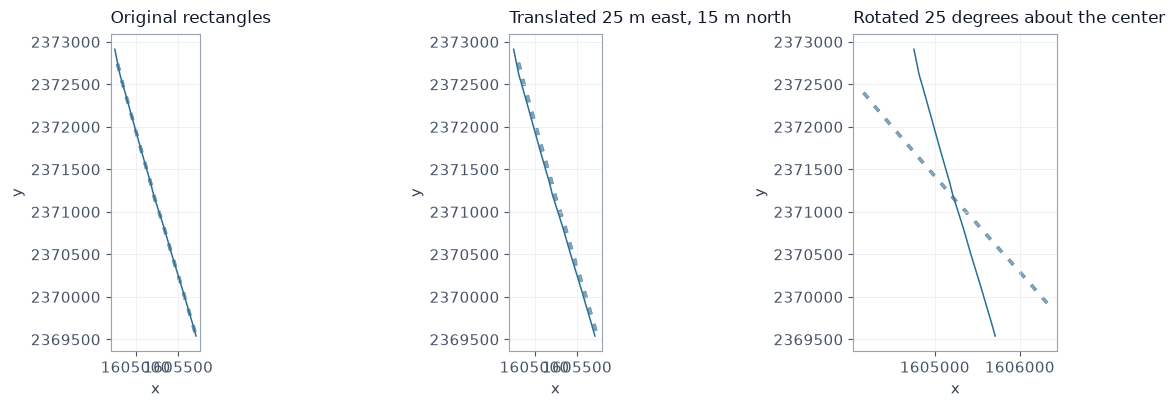

In [11]:
# Numeric affine check on a probe point, then translate / rotate / scale plots.
# Midpoint of North Road used as the transform origin.
anchor = road.geometry.iloc[0].interpolate(0.5, normalized=True)
# Probe point 80 m east of the midpoint.
probe = gpd.GeoDataFrame(
    {"name": ["probe"]},  # one map layer: data plus draw style
    geometry=[Point(anchor.x + 80, anchor.y)],  # active geometry column or list of geometries
    crs=road.crs,  # coordinate reference system
# close the function call
)
# Scale 2, rotate 90 degrees CCW, then translate (10, -5) about the anchor.
ordered = affine_transform(
    probe,  # input point for the ordered affine check
    scale=2,  # double distance from the origin
    angle=90,  # rotate counterclockwise
    translation=(10, -5),  # apply last: +10 east, -5 north
    origin=(anchor.x, anchor.y),  # shared origin for scale and rotate
)
# Print start, transformed, and expected coordinates for the ordered steps.
print(f"Start:    ({probe.geometry.iloc[0].x:,.2f}, {probe.geometry.iloc[0].y:,.2f})")
print(f"Affine:   ({ordered.geometry.iloc[0].x:,.2f}, {ordered.geometry.iloc[0].y:,.2f})")  # print a short status line
print(f"Expected: ({anchor.x + 10:,.2f}, {anchor.y + 160 - 5:,.2f})")  # print a short status line

# Shift every rectangle 25 m east and 15 m north.
shifted = translate(rect_plots, xoff=25, yoff=15)
# Rotate the plot row 25 degrees about the layer center.
turned = rotate(rect_plots, 25)
# Scale each plot 1.5x in X about its own centroid (area should grow).
resized = affine_transform(rect_plots, scale=(1.5, 1), origin="feature")
# print a short status line
print(f"Feature scale changes the area from {rect_plots.geometry.area.iloc[0]:,.0f} to {resized.geometry.area.iloc[0]:,.0f} square metres")

# Three maps: original, translated, and rotated rectangles on the road.
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
# (layer, title) pairs for the three transform panels
layers = [
    (rect_plots, "Original rectangles"),  # original plots panel
    (shifted, "Translated 25 m east, 15 m north"),  # translated plots panel
    (turned, "Rotated 25 degrees about the center"),  # rotated plots panel
# close the list of (layer, title) pairs
]
# iterate over panels (or rows) to draw each map
for ax, (layer, title) in zip(axes, layers):
    plot_layer(road, ax=ax, edgecolor="#98A2B3", linewidth=1.1, show=False)
    plot_layer(layer, title, ax=ax, alpha=0.6, linewidth=0.3, show=False)
fig.tight_layout()  # tighten subplot spacing
plt.show()  # render the figure



### Orthogonalize

`orthogonalize()` moves a corner onto a right angle when the corner is already close to 90 degrees. The two neighboring vertices stay fixed, and the corner moves the shortest distance onto that right angle. `angle_tolerance` is how far from 90 degrees a corner may be and still be squared. `max_iterations` is the number of passes over the vertices.

Broomfield County is a published boundary, so this is a demonstration of the move. A tolerance of 15 degrees squares the corners that are already near a right angle and changes the county area. On a hand-digitized plot the same call is used with a tolerance that matches the digitizing error.


Area before: 86.232 square kilometres
Area after:  88.803 square kilometres


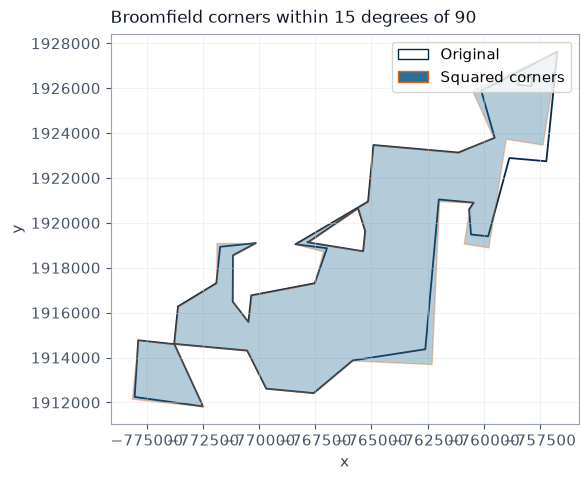

<Axes: title={'left': 'Broomfield corners within 15 degrees of 90'}, xlabel='x', ylabel='y'>

In [12]:
# Square Broomfield corners that are already within 15 degrees of 90.
squared = orthogonalize(broomfield, angle_tolerance=15)
# Compare area before and after (square kilometres).
print(f"Area before: {broomfield.geometry.area.iloc[0] / 1e6:,.3f} square kilometres")
print(f"Area after:  {squared.geometry.area.iloc[0] / 1e6:,.3f} square kilometres")  # print a short status line
# Overlay the squared outline on the original boundary.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        # one map layer: data plus draw style
        {"data": broomfield, "label": "Original", "facecolor": "none", "edgecolor": EDGE, "linewidth": 1.3},
        {"data": squared, "label": "Squared corners", "facecolor": FACE, "alpha": 0.35, "edgecolor": "#E36414", "linewidth": 1.0},
    ],
    title="Broomfield corners within 15 degrees of 90",  # map title
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Snap points to a grid

`snap_points_to_grid()` rounds every vertex to the nearest grid intersection. The grid size is `spacing_x` by `spacing_y`. When `spacing_y` is omitted the cells are square. Coordinates that land on a cell boundary round half away from zero.

The Colorado samples are rounded onto a 5 kilometre grid. `shift_m` is how far each sample moved. The map zooms to the county of the sample that moved the farthest.


,ID,COUNTY,shift_m,grid_x,grid_y
125,126,Kit Carson County,3407.334430,-555000.0,1845000.0
96,97,Pueblo County,3339.441622,-710000.0,1730000.0
104,105,Morgan County,3276.593951,-640000.0,1925000.0
60,61,Grand County,3259.257833,-835000.0,1945000.0
59,60,Saguache County,3220.793808,-860000.0,1730000.0
18,19,Rio Blanco County,3163.376030,-1005000.0,1940000.0
77,78,Las Animas County,3150.494059,-785000.0,1600000.0
127,128,Prowers County,3135.475869,-560000.0,1675000.0


Largest shift: 3,407.3 m in Kit Carson County


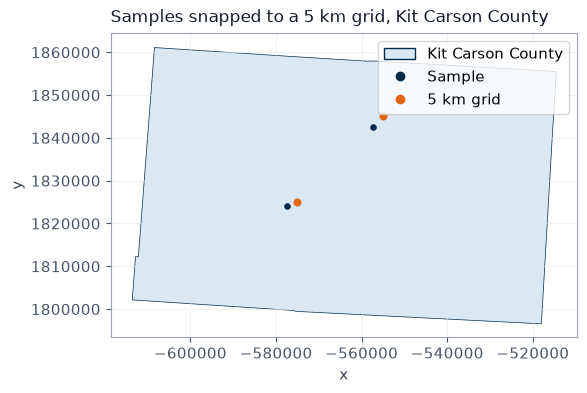

<Axes: title={'left': 'Samples snapped to a 5 km grid, Kit Carson County'}, xlabel='x', ylabel='y'>

In [13]:
# Snap Colorado soil samples to a 5 km grid and map the farthest county.
snapped = snap_points_to_grid(samples, 5000)  # 5000 m spacing
# Align indices so shift distances line up row-for-row.
placed = samples.reset_index(drop=True).copy()
# Distance each sample moved when snapped to the grid.
placed["shift_m"] = samples.reset_index(drop=True).geometry.distance(snapped.geometry).to_numpy()
placed["grid_x"] = snapped.geometry.x.to_numpy()  # snapped easting
placed["grid_y"] = snapped.geometry.y.to_numpy()  # snapped northing
# Show the eight samples with the largest shifts.
display(
    placed[["ID", "COUNTY", "shift_m", "grid_x", "grid_y"]]  # start from sample shift columns
    .sort_values("shift_m", ascending=False)  # largest grid shifts first
    .head(8)  # keep only the top rows for display
# close the function call
)

# County containing the sample that moved the farthest.
farthest = placed["shift_m"].idxmax()
county_name = placed.loc[farthest, "COUNTY"]  # county of the sample with the largest shift
county_mask = placed["COUNTY"] == county_name  # boolean mask for that county
county_poly = co_counties.loc[co_counties["COUNTY"] == county_name]
print(f"Largest shift: {placed.loc[farthest, 'shift_m']:,.1f} m in {county_name}")  # print a short status line

# Zoom map: county outline, original samples, and snapped grid points.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        {"data": county_poly, "label": county_name, "facecolor": "#D9E8F2", "edgecolor": EDGE, "linewidth": 0.5},
        {"data": placed.loc[county_mask], "label": "Sample", "facecolor": EDGE, "markersize": 18},
        {"data": snapped.loc[county_mask.to_numpy()], "label": "5 km grid", "facecolor": "#E36414", "markersize": 28},
    ],
    title=f"Samples snapped to a 5 km grid, {county_name}",  # map title
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Snap geometries to a layer

`snap_geometries_to_layer()` moves vertices of `data` onto `reference` when a target is within `tolerance`.

* `"vertices"` snaps to reference vertices.
* `"segments"` snaps to the nearest location on a reference edge.
* `"vertices_and_segments"` uses a vertex when one is in range, and otherwise uses an edge. This is the default. A vertex inside the tolerance wins over a closer edge.

Passing the same layer as `data` and `reference` closes small gaps between features. Vertices within the tolerance collapse to one anchor, the vertex closest to the group centroid.

Colorado counties are snapped to themselves with a 50 metre tolerance. `area_change_m2` is the area of the symmetric difference, so it measures how much boundary moved.


In [14]:
# Snap Colorado counties to themselves to close small boundary gaps.
closed = snap_geometries_to_layer(co_counties, co_counties, 50)  # 50 m tolerance
# Align indices with the snapped result for pairwise comparison.
original = co_counties.reset_index(drop=True)
# Area of the symmetric difference measures how much each boundary moved.
change = [
    left.symmetric_difference(right).area  # area where the original and snapped boundaries differ
    for left, right in zip(original.geometry, closed.geometry)  # pair each original geometry with its snapped copy
# close the list of (layer, title) pairs
]
# Attach the change values to county names for ranking.
report = original[["COUNTY"]].copy()
report["area_change_m2"] = change  # store the boundary-change area per county
report = report.sort_values("area_change_m2", ascending=False)  # rank counties by how much the boundary moved
# Count counties whose boundary area change exceeds 1 square metre.
moved = int((report["area_change_m2"] > 1).sum())
print(f"Counties with a boundary change above 1 square metre: {moved} of {len(report)}")  # print a short status line
display(report.head(8))  # preview the table in the notebook



Counties with a boundary change above 1 square metre: 20 of 64


,COUNTY,area_change_m2
45,Kiowa County,235795.308590
47,Prowers County,229980.946414
14,Baca County,158002.611341
38,Sedgwick County,145730.404386
60,Broomfield County,33345.104905
63,Jefferson County,33212.469989
61,Las Animas County,15884.314120
4,Phillips County,14781.392495


### Build sections

`build_sections()` has two modes.

Grid mode lays out rectangles. `width` and `height` are the cell size. The southwest corner of the layer is the origin when `origin` is omitted. `rows` and `columns` are counted from that extent when they are omitted. `angle` rotates the whole grid about the origin. Row 1 is the southern row before rotation. Each cell is named `R{row}C{column}`.

Attribute mode is selected with `by`. Features that share the attribute are unioned into one polygon. Other attributes are aggregated with `aggfunc`, using the same names as `dissolve()`. `n_features` counts the input features in the section.

The grid below covers Broomfield County with 4 kilometre cells. The attribute example unions US states that share a census `REGION`.


Section cells: 20


,section,row,column
0,R1C1,1,1
1,R1C2,1,2
2,R1C3,1,3
3,R1C4,1,4
4,R1C5,1,5
5,R2C1,2,1
6,R2C2,2,2
7,R2C3,2,3


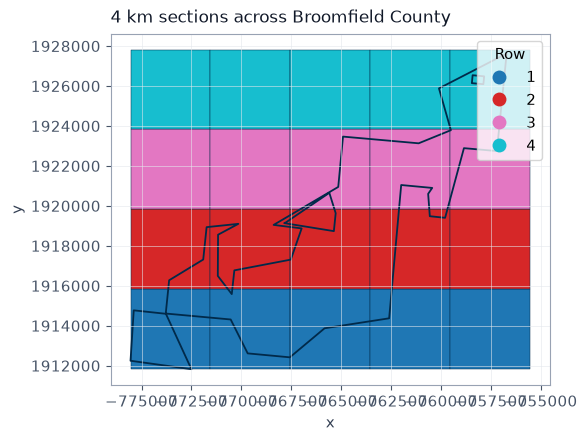

In [15]:
# Cover Broomfield with a 4 km by 4 km labeled section grid.
section_grid = build_sections(broomfield, width=4000, height=4000)
print(f"Section cells: {len(section_grid)}")  # print a short status line
# Preview section names and row/column indices.
display(section_grid[["section", "row", "column"]].head(8))

fig, ax = plt.subplots(figsize=(6, 5))  # create figure and axes for the section grid map
# Color cells by row index and draw a legend.
plot_layer(
    section_grid,  # 4 km section polygons to plot
    ax=ax,  # target matplotlib axes
    column="row",  # attribute used for symbology
    categorical=True,  # treat the column as categories, not a continuous ramp
    legend=True,  # show a legend
    linewidth=0.35,  # outline width
    legend_kwds={"title": "Row", "loc": "best"},  # legend title and placement
    show=False,  # defer plt.show so callers can compose axes
# close the function call
)
# Overlay the county outline on the grid.
plot_layer(broomfield, ax=ax, facecolor="none", edgecolor=EDGE, linewidth=1.3, show=False)
style_axes(ax, "4 km sections across Broomfield County")  # apply shared axis styling and title
fig.tight_layout()  # tighten subplot spacing
plt.show()  # render the figure



,REGION,n_features,area_km2
3,Midwest,12,1.984555e+06
2,Northeast,9,4.364757e+05
0,South,17,2.315430e+06
1,West,11,3.073551e+06


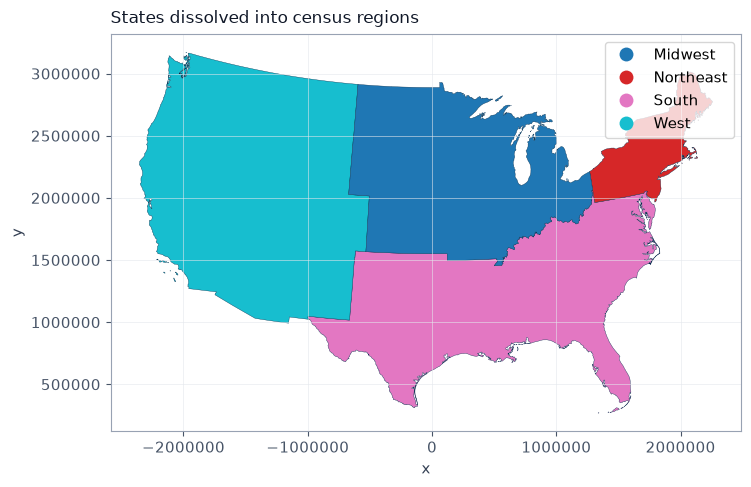

<Axes: title={'left': 'States dissolved into census regions'}, xlabel='x', ylabel='y'>

In [16]:
# Attribute-mode sections: dissolve US states by census REGION.
regions = build_sections(states, by="REGION")  # one polygon per region
regions = regions.copy()  # allow adding a computed column
regions["area_km2"] = regions.geometry.area / 1e6  # square metres to km2
# Sort regions alphabetically for a tidy table.
display(regions[["REGION", "n_features", "area_km2"]].sort_values("REGION"))
# Choropleth of the dissolved census regions.
plot_layer(
    regions,  # census-region polygons to plot
    "States dissolved into census regions",  # keyword or positional argument continued
    column="REGION",  # attribute used for symbology
    categorical=True,  # treat the column as categories, not a continuous ramp
    legend=True,  # show a legend
    linewidth=0.25,  # outline width
    figsize=(8, 5),  # figure width and height in inches
# close the function call
)



## Part 3: Measure and clean

### Geometry attributes

`add_geometry_attributes()` measures each geometry in the units of the layer CRS.

Polygons can receive `area` and `perimeter`. Perimeter includes holes, and area excludes holes. Lines can receive `length`. Points can receive `x` and `y`, and `z` when a point has a Z coordinate. A column is added only when the layer contains that geometry family and the matching flag is True.

The three calls below measure Colorado counties, North Road, and the first soil samples. The sample layer already has `x` and `y` fields. Those fields are rewritten from the point coordinates.


In [17]:
# Measure area/perimeter for counties, length for the road, and x/y for samples.
county_measures = add_geometry_attributes(co_counties)
# Keep a slim view with area and perimeter converted to km units.
county_view = county_measures[["COUNTY", "area", "perimeter"]].copy()
county_view["area_km2"] = county_view["area"] / 1e6  # convert square metres to square kilometres
county_view["perimeter_km"] = county_view["perimeter"] / 1000  # convert metres to kilometres
# Five largest counties by area.
display(county_view.sort_values("area", ascending=False).head(5).loc[:, ["COUNTY", "area_km2", "perimeter_km"]])

# Line length for North Road.
road_measures = add_geometry_attributes(road)
print(f"North Road length: {road_measures['length'].iloc[0]:,.1f} m")  # print a short status line
print("Columns on the line layer:", [name for name in road_measures.columns if name != "geometry"])  # print a short status line

# Point x/y attributes for the first five samples (rewritten from geometry).
sample_measures = add_geometry_attributes(samples.head(5))
display(sample_measures[["ID", "COUNTY", "x", "y"]])  # preview the table in the notebook



,COUNTY,area_km2,perimeter_km
61,Las Animas County,12373.377954,514.238150
0,Moffat County,12291.900543,465.695699
40,Weld County,10400.946028,482.884660
34,Mesa County,8657.392135,460.088219
32,Gunnison County,8443.975137,490.495035


North Road length: 3,525.0 m
Columns on the line layer: ['ID', 'DateModifi', 'NYSStreetI', 'LeftFromAd', 'LeftToAddr', 'RightFromA', 'RightToAdd', 'CompleteSt', 'PreModifie', 'PreDirecti', 'PreType', 'SeparatorE', 'StreetName', 'PostType', 'PostDirect', 'PostModifi', 'SHIELD', 'HighwayNum', 'Navigation', 'JURISDICTI', 'FCC', 'ACC', 'SPEED', 'OneWay', 'FromZlev', 'ToZlev', 'FromToDire', 'ToFromDire', 'FromToCost', 'ToFromCost', 'LeftStateN', 'RightState', 'LeftCounty', 'RightCount', 'LeftPostal', 'RightPosta', 'LeftZipNam', 'RightZipNa', 'LeftCityTo', 'RightCityT', 'LeftPlaceN', 'RightPlace', 'LeftGNIS', 'RightGNIS', 'LeftCensus', 'RightCensu', 'GeometryAc', 'GeometrySo', 'NameSource', 'AddressSou', 'Status', 'CLDXF_PreD', 'CLDXF_Post', 'CLDXF_Po_1', 'Label', 'CR_USERNAM', 'CR_DATETIM', 'AT_USERNAM', 'AT_DATETIM', 'SP_USERNAM', 'SP_DATETIM', 'USERNAME', 'LeftCountr', 'RightCou_1', 'LeftParity', 'RightParit', 'LeftESN', 'RightESN', 'Shape_Leng', 'length']


,ID,COUNTY,x,y
0,1,Moffat County,-1093437.57,2012102.53
1,2,Montezuma County,-1126354.83,1693198.83
2,3,Mesa County,-1098195.83,1873435.33
3,4,Mesa County,-1096914.83,1831385.01
4,5,Garfield County,-1082424.11,1904322.66


### Collect geometries

`collect_geometries()` groups features into one multipart geometry and does not union the parts. Two overlapping polygons stay two parts of a `MultiPolygon`, so the collected area can be larger than the dissolved area. `build_sections(..., by=)` unions each group into one polygon.

States in the same census region share borders and do not overlap, so the areas match. The geometry type shows the difference: `collect_geometries()` keeps one part per state, and `build_sections()` dissolves those states into a region polygon. `n_features` is the number of states in the group.


In [18]:
# Collect states by REGION (multipart) and compare areas to dissolved sections.
collected = collect_geometries(states, by="REGION")  # multipart, no dissolve
collected = collected.copy()
collected["area_km2"] = collected.geometry.area / 1e6  # measured area of the collect
collected["geom_type"] = collected.geometry.geom_type  # MultiPolygon vs Polygon
# Bring in dissolved areas from the earlier build_sections result.
dissolved = regions[["REGION", "area_km2", "n_features"]].rename(columns={"area_km2": "dissolved_km2"})
# Join on region and feature count so rows line up.
comparison = collected[["REGION", "n_features", "geom_type", "area_km2"]].merge(dissolved, on=["REGION", "n_features"])
display(comparison.sort_values("REGION"))  # preview the table in the notebook



,REGION,n_features,geom_type,area_km2,dissolved_km2
3,Midwest,12,MultiPolygon,1.984555e+06,1.984555e+06
2,Northeast,9,MultiPolygon,4.364757e+05,4.364757e+05
0,South,17,MultiPolygon,2.315430e+06,2.315430e+06
1,West,11,MultiPolygon,3.073551e+06,3.073551e+06


### Centroids and point on surface

`centroids()` returns the center of mass. For a concave polygon, or for a multipolygon whose parts are separated, that point can fall outside the feature.

`point_on_surface()` returns a point that lies in the polygon interior, on the line, or on the point itself.

Island County, Washington, is drawn as more than one island. Its centroid falls in the water between the islands. The point on surface falls on land.


Geometry type: MultiPolygon
Centroid inside the county: False
Point on surface inside the county: True


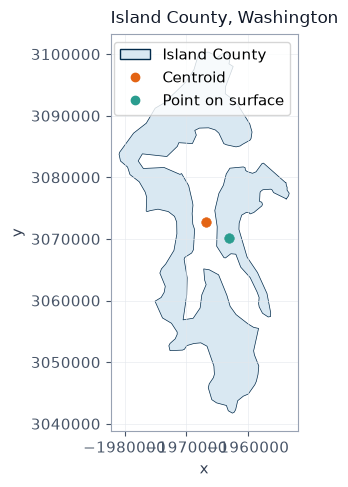

<Axes: title={'left': 'Island County, Washington'}, xlabel='x', ylabel='y'>

In [19]:
# Compare centroid vs point-on-surface for multipolygon Island County, WA.
island = counties.loc[
    (counties["STATE"] == "Washington") & (counties["COUNTY"] == "Island County")  # Island County is a multipolygon in Washington
].copy()  # copy so later cells can edit safely
center = centroids(island)  # center of mass (can fall in water)
marker = point_on_surface(island)  # guaranteed on land
print(f"Geometry type: {island.geometry.iloc[0].geom_type}")
# Test whether each candidate point lies inside the county geometry.
print(f"Centroid inside the county: {bool(center.geometry.iloc[0].within(island.geometry.iloc[0]))}")
# print a short status line
print(f"Point on surface inside the county: {bool(marker.geometry.iloc[0].within(island.geometry.iloc[0]))}")
# Map both candidate points on the county outline.
plot_layers(
    # each dict is one layer: data plus draw style
    [
        {"data": island, "label": "Island County", "facecolor": "#D9E8F2", "edgecolor": EDGE, "linewidth": 0.5},
        {"data": center, "label": "Centroid", "facecolor": "#E36414", "markersize": 48},
        {"data": marker, "label": "Point on surface", "facecolor": "#2A9D8F", "markersize": 48},
    ],
    title="Island County, Washington",  # map title
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Points displacement

`points_displacement()` is for point records that share one coordinate. Points within `proximity` of each other form one stack. `proximity=0` groups coordinates that match to 8 decimal places. A stack is moved onto a circle of radius `distance` around the stack centroid. The first feature is placed at `start_angle` degrees counterclockwise from east, and the rest follow counterclockwise. A point that is alone stays where it is. `displacement_group` identifies the stack. Alone points keep a missing group value.

Street centerlines around North Road reuse the same vertex where segments meet. Those vertices are extracted as points and spread by 12 metres so each copy of a shared node is visible. The map is a 40 metre window around the largest stack.


Segments in the 250 m corridor: 4
Vertices: 45
Stacks: 2


,vertices
displacement_group,
16,3
1,2


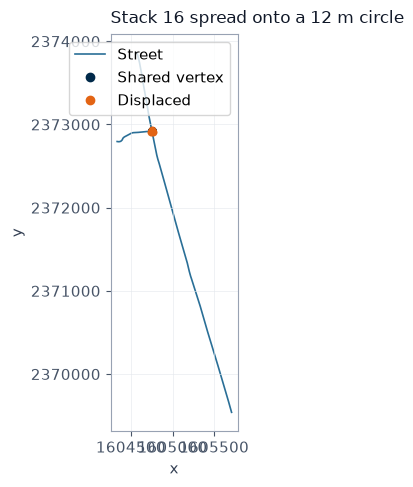

<Axes: title={'left': 'Stack 16 spread onto a 12 m circle'}, xlabel='x', ylabel='y'>

In [20]:
# Extract shared street vertices near North Road and spread stacked points.
# 250 m buffer around North Road defines the search corridor.
corridor = road.geometry.iloc[0].buffer(250)
# Keep street segments that intersect the corridor.
nearby = streets.loc[streets.geometry.intersects(corridor)].copy()
node_rows = []  # accumulate one point record per vertex
for _, record in nearby.iterrows():
    # Explode every vertex of the segment into its own point feature.
    for coord in record.geometry.coords:
        # append one point feature for this vertex
        node_rows.append({"StreetName": record["StreetName"], "geometry": Point(coord[0], coord[1])})
# Build a GeoDataFrame of all corridor vertices.
nodes = gpd.GeoDataFrame(node_rows, geometry="geometry", crs=streets.crs)
# Spread exact-coordinate stacks onto a 12 m circle, starting at 90 degrees.
spread = points_displacement(nodes, distance=12, proximity=0, start_angle=90)
# Count how many vertices landed in each displacement stack.
counts = spread["displacement_group"].value_counts(dropna=True)
print(f"Segments in the 250 m corridor: {len(nearby)}")  # print a short status line
print(f"Vertices: {len(nodes)}")  # print a short status line
print(f"Stacks: {len(counts)}")  # print a short status line
display(counts.rename("vertices").rename_axis("displacement_group").to_frame())  # preview the table in the notebook

# Zoom to a 40 m window around the largest stack.
group_id = counts.index[0]  # most common displacement group
group = spread.loc[spread["displacement_group"] == group_id]
focus = group.geometry.union_all().centroid  # window center
window = 40  # half-width of the map window in metres
# Clip streets / nodes / spread points to that window with .cx.
local_streets = nearby.cx[focus.x - window : focus.x + window, focus.y - window : focus.y + window]
local_nodes = nodes.cx[focus.x - window : focus.x + window, focus.y - window : focus.y + window]  # same map window for original shared vertices
local_spread = spread.cx[focus.x - window : focus.x + window, focus.y - window : focus.y + window]  # same map window for displaced copies
# compose the map from styled layer dicts
plot_layers(
    # each dict is one layer: data plus draw style
    [
        {"data": local_streets, "label": "Street", "edgecolor": "#98A2B3", "linewidth": 1.2},
        {"data": local_nodes, "label": "Shared vertex", "facecolor": EDGE, "markersize": 36},
        {"data": local_spread, "label": "Displaced", "facecolor": "#E36414", "markersize": 28},
    ],
    title=f"Stack {group_id} spread onto a 12 m circle",  # map title
    figsize=(6, 5),  # figure width and height in inches
# close the function call
)



### Check and fix geometry

`check_validity()` adds `is_valid` and `validity_reason` to every feature. `invalid_only=True` returns only the rows that failed. Run this before publishing an area.

`fix_geometries()` repairs invalid geometries. `method="make_valid"` uses the GEOS make-valid operation and keeps the original vertex locations. `method="buffer"` uses a zero-width buffer. A geometry that is already valid is copied through unchanged.

The Colorado county layer in this dataset is valid, so the repair leaves the geometries in place.


In [21]:
# Check Colorado county validity, then run fix_geometries (should be a no-op).
validity = check_validity(co_counties)  # adds is_valid and validity_reason
print(validity["is_valid"].value_counts().to_string())
display(validity[["COUNTY", "is_valid", "validity_reason"]].head())  # preview the table in the notebook
# Keep only rows that failed the validity test (expect zero here).
invalid = check_validity(co_counties, invalid_only=True)
print(f"Invalid counties: {len(invalid)}")  # print a short status line

# Repair invalid geometries; valid ones are copied through unchanged.
fixed = fix_geometries(co_counties)
# True when every repaired geometry equals the corresponding input.
same = all(
    left.equals(right)  # True when the repaired geometry matches the input
    for left, right in zip(co_counties.geometry, fixed.geometry)  # pair each input geometry with its repaired copy
# close the function call
)
print(f"All repaired geometries are valid: {bool(fixed.geometry.is_valid.all())}")  # print a short status line
print(f"Valid input copied through unchanged: {same}")  # print a short status line



is_valid
True    64


,COUNTY,is_valid,validity_reason
0,Moffat County,True,Valid Geometry
1,Yuma County,True,Valid Geometry
2,Garfield County,True,Valid Geometry
3,Jackson County,True,Valid Geometry
4,Phillips County,True,Valid Geometry


Invalid counties: 0
All repaired geometries are valid: True
Valid input copied through unchanged: True


### Remove duplicate vertices

`remove_duplicate_vertices()` drops consecutive vertices that are closer than `tolerance`. `tolerance=0` removes exact duplicates and keeps every distinct corner. A positive tolerance also collapses a short segment. A ring that would lose its shape becomes empty. Points are unchanged.

North Road has no exact duplicate vertices. Its shortest segment is shorter than 40 metres, so a 40 metre tolerance removes that vertex and shortens the line.


Vertices in North Road: 16
Shortest segment: 32.4 m
Vertices after tolerance 0: 16
Vertices after tolerance 40 m: 15
Length before: 3,525.0 m
Length after 40 m tolerance: 3,524.9 m


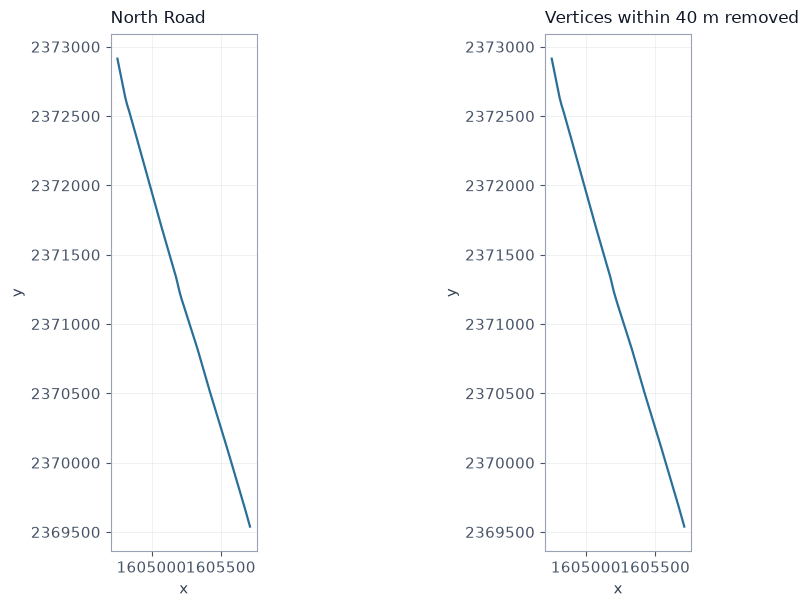

(<Figure size 1000x620 with 2 Axes>,
 array([<Axes: title={'left': 'North Road'}, xlabel='x', ylabel='y'>,
        <Axes: title={'left': 'Vertices within 40 m removed'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [22]:
# Measure vertex spacing on North Road, then remove near-duplicate vertices.
coords = list(road.geometry.iloc[0].coords)  # ordered (x, y) vertices
# Distance between each consecutive vertex pair.
gaps = [
    Point(start).distance(Point(end))  # length of the segment between consecutive vertices
    for start, end in zip(coords, coords[1:])  # consecutive vertex pairs along the line
# close the list of (layer, title) pairs
]
# tolerance=0 drops exact duplicates only.
exact = remove_duplicate_vertices(road, tolerance=0)
# tolerance=40 also collapses vertices within 40 metres.
collapsed = remove_duplicate_vertices(road, tolerance=40)
print(f"Vertices in North Road: {len(coords)}")  # print a short status line
print(f"Shortest segment: {min(gaps):,.1f} m")  # print a short status line
print(f"Vertices after tolerance 0: {len(list(exact.geometry.iloc[0].coords))}")  # print a short status line
print(f"Vertices after tolerance 40 m: {len(list(collapsed.geometry.iloc[0].coords))}")  # print a short status line
print(f"Length before: {road.geometry.length.iloc[0]:,.1f} m")  # print a short status line
print(f"Length after 40 m tolerance: {collapsed.geometry.length.iloc[0]:,.1f} m")  # print a short status line
# Compare the original line with the simplified one.
plot_pair(
    road,  # original North Road line
    collapsed,  # North Road after near-duplicate vertices were removed
    ["North Road", "Vertices within 40 m removed"],  # panel titles for the before/after pair
    figsize=(10, 6.2),  # figure width and height in inches
    linewidth=1.6,  # outline width
# close the function call
)



### Delete holes

`delete_holes()` removes interior rings from polygons. `minimum_area=0` deletes every hole. A positive `minimum_area` deletes only holes smaller than that value. Lines and points are returned unchanged.

Broomfield County contains two holes. The first call removes both. The second call keeps any hole of at least 1 square kilometre and deletes the smaller one. Area goes up by the area of the holes that were removed, because polygon area excludes holes.


Holes: 2
Hole 1: 2.504 square kilometres
Hole 2: 0.230 square kilometres
Holes after deleting all: 0
Holes at least 1 square kilometre kept: 1
Area with holes: 86.232 square kilometres
Area with holes removed: 88.967 square kilometres


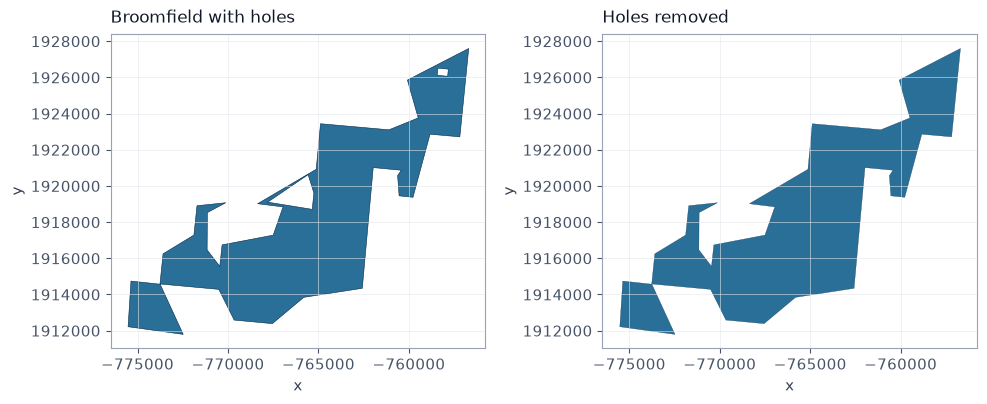

(<Figure size 1000x450 with 2 Axes>,
 array([<Axes: title={'left': 'Broomfield with holes'}, xlabel='x', ylabel='y'>,
        <Axes: title={'left': 'Holes removed'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [23]:
# Measure Broomfield holes, then delete all holes vs keep large ones.
polygon = broomfield.geometry.iloc[0]  # county geometry (may have interiors)
# Area of each interior ring treated as its own polygon.
hole_areas = [Polygon(ring).area for ring in polygon.interiors]
print(f"Holes: {len(hole_areas)}")  # print a short status line
# iterate over panels (or rows) to draw each map
for index, area in enumerate(hole_areas, start=1):
    print(f"Hole {index}: {area / 1e6:,.3f} square kilometres")  # print a short status line

# Delete every interior ring.
cleared = delete_holes(broomfield)
# Keep holes whose area is at least 1 square kilometre (1_000_000 m2).
kept = delete_holes(broomfield, minimum_area=1_000_000)
print(f"Holes after deleting all: {len(list(cleared.geometry.iloc[0].interiors))}")  # print a short status line
print(f"Holes at least 1 square kilometre kept: {len(list(kept.geometry.iloc[0].interiors))}")  # print a short status line
print(f"Area with holes: {polygon.area / 1e6:,.3f} square kilometres")  # print a short status line
print(f"Area with holes removed: {cleared.geometry.area.iloc[0] / 1e6:,.3f} square kilometres")  # print a short status line
# Side-by-side map of original vs hole-free county.
plot_pair(
    broomfield,  # county polygon that still has holes
    cleared,  # same county after all holes were deleted
    ["Broomfield with holes", "Holes removed"],  # panel titles for the before/after pair
    figsize=(10, 4.5),  # figure width and height in inches
# close the function call
)



## Summary

Every geometry operation in `geolattice.vector.geometry_tools` was applied to the US state and county layers, the Colorado soil samples, North Road in Onondaga County, or the Yellowstone boundary.

| Operation | What it does | Example in this notebook |
|---|---|---|
| Oriented box | Rotated rectangle around a layer or around each feature, with the long-side angle | Yellowstone, and one box per Colorado county |
| Offset lines | Parallel copies of a line, indexed from the line direction | Three copies on each side of North Road at 40 m |
| Points along a line | Points at a fixed spacing, with `distance_along` | Stations every 200 m on North Road |
| Rectangles, ovals, diamonds | Fixed-size polygons centered on points and rotated by an angle | 80 m by 36 m plots turned onto the road angle |
| Transects | Lines across a path at a vertex or at a regular interval | 160 m lines every 200 m along North Road |
| Translate | Same easting and northing shift for every feature | Plots moved 25 m east and 15 m north |
| Rotate | One rotation about the layer center, the centroid, each feature, or a point | Plots turned 25 degrees about their center |
| Affine transform | Scale, then rotation, then translation | A probe point scaled, turned 90 degrees, then shifted |
| Orthogonalize | Corners already near 90 degrees move onto a right angle | Broomfield County with a 15 degree tolerance |
| Snap to a grid | Vertices round to a regular spacing | Soil samples on a 5 km grid |
| Snap to a layer | Vertices within a tolerance move onto a reference layer | Colorado counties snapped to themselves at 50 m |
| Build sections | A labeled rectangle grid, or a union of features that share an attribute | 4 km cells on Broomfield, and states dissolved by region |
| Geometry attributes | Area, perimeter, length, and point coordinates | County area, North Road length, and sample coordinates |
| Collect geometries | Multipart group without dissolving overlaps | States collected by census region |
| Centroids | Center of mass, which can fall outside the feature | Island County, Washington |
| Point on surface | A point guaranteed to lie in the feature | The same county, with the point on land |
| Points displacement | Stacked points spread onto a circle | Shared street vertices around North Road |
| Check validity | `is_valid` and a reason for every feature | Colorado counties |
| Fix geometries | Repairs invalid geometry and copies valid geometry through | The same county layer |
| Remove duplicate vertices | Drops exact or near-duplicate corners | A 40 m tolerance on North Road |
| Delete holes | Removes interior rings, or only rings smaller than an area | Both holes in Broomfield, then only the smaller hole |

Angles are degrees counterclockwise from east. Distances are in the units of the layer. These layers are in metres.




The geometry tools cover the constructions used to lay out plots and the cleanup used before an area is published. Start from a line or a set of points, build parallel rows and stations, and turn those stations into rectangles, ovals, or diamonds aligned with `oriented_minimum_bounding_box()`. `transect()`, `rotate()`, `translate()`, and `affine_transform()` place that layout on the ground.

On polygons, `orthogonalize()`, `snap_points_to_grid()`, and `snap_geometries_to_layer()` repair corners and close gaps. `delete_holes()` and `remove_duplicate_vertices()` simplify rings. `check_validity()` and `fix_geometries()` belong before `add_geometry_attributes()`. `centroids()` and `point_on_surface()` make label points. `build_sections()` and `collect_geometries()` group features into sections, and only the section builder unions overlapping area.

Read each shapefile with `open_vectors_data()`, then pass the layer to the geometry function. Project a geographic layer before using a width, spacing, or tolerance as a ground distance.


### Further reading

**GeoLattice**

* `open_vectors_data()` reads the shapefiles in `Data/00_shared/vector_data/USA`.
* The geometry functions in this notebook are exported from `geolattice.vector` and implemented in `geolattice/vector/geometry_tools.py`.
* `plot_layer()`, `plot_layers()`, `plot_pair()`, and `style_axes()` are in `geolattice.viz`.

**Libraries used by those functions**

* [Shapely](https://shapely.readthedocs.io/): geometry construction, affine transforms, `offset_curve`, validity, and `make_valid`.
* [GeoPandas](https://geopandas.org/): GeoDataFrames returned by the geometry tools, and the maps in this notebook.
* [pandas](https://pandas.pydata.org/docs/): attribute tables copied onto the new geometries.
* [Matplotlib](https://matplotlib.org/): the figures in this notebook.

**Data**

* State, county, soil-sample, street, and park shapefiles are in `Data/00_shared/vector_data/USA`.
* The Yellowstone National Park boundary is published by the National Park Service on [Data.gov](https://catalog.data.gov/dataset/national-park-boundariesf0a4c).
